# Kepler Exoplanet Classification: complete project

**Goal.** Classify NASA Kepler *Objects of Interest* (KOI) as **CONFIRMED** exoplanets or **FALSE POSITIVE** signals, using the physical measurements of each transit signal.

**Data.** NASA Exoplanet Archive, *Cumulative KOI* table: 9,564 rows × 141 columns. The CANDIDATE rows (no verdict yet) are only used at the end, for screening.

**Main challenge: data leakage.** Some columns are produced by the classification process itself (NASA's score, the pipeline verdict, the false-positive flags, the planet name). Keeping them would give about 99% accuracy by cheating. They are removed before any modelling.

**What this notebook does, in order**

- **Part A: Data understanding.** Loading, leakage removal, cleaning, exploratory analysis.
- **Part B: Preprocessing.** Leak-free preprocessing, stratified split, reusable pipeline.
- **Part C: Baselines.** Dummy, Logistic Regression, Random Forest, gradient boosting, all in 5-fold cross-validation.
- **Part D: Improvements.** PCA with/without, tuning, calibration, cost-based threshold, sensitivity check, explainability.
- **Part E: Final evaluation.** One held-out test set, error analysis.
- **Part F: Business applications.** Follow-up prioritisation and CANDIDATE screening.
- **Part G: Saved artefacts and conclusions.**

**Rules followed throughout.** Every modelling choice (model, PCA, hyperparameters, calibration method, decision threshold) is made with cross-validation **on the training set only**. The test set is used once for the final comparison.

**How to run.** Put `koi_cumulative.csv` in `data/raw/`, keep the notebook in `notebooks/`, and run all cells (about 2 to 3 minutes on a laptop).

connexion au Drive

In [1]:
import os

try:
    from google.colab import drive
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    drive.mount("/content/drive")
    PROJECT = "/content/drive/MyDrive/kepler-exoplanet-classification"
    if not os.path.exists(PROJECT):
        raise FileNotFoundError("Dossier introuvable sur Drive : " + PROJECT)
    os.chdir(PROJECT + "/notebooks")

print("Working directory:", os.getcwd())

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Working directory: /content/drive/MyDrive/kepler-exoplanet-classification/notebooks


In [2]:
import os
print(os.path.exists("/content/drive/MyDrive/kepler-exoplanet-classification/data/raw/koi_cumulative.csv"))

True


## 0. Setup

In [3]:
import warnings  # masque les messages d'avertissement pour garder l'affichage lisible
warnings.filterwarnings("ignore")  # keeps the outputs readable

import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.base import clone
from sklearn.model_selection import (train_test_split, StratifiedKFold, cross_validate,
                                     cross_val_score, cross_val_predict, RandomizedSearchCV)
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.metrics import (f1_score, accuracy_score, precision_score, recall_score,
                             confusion_matrix, ConfusionMatrixDisplay, brier_score_loss, log_loss)
from sklearn.inspection import permutation_importance

RANDOM_STATE = 42
CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
pd.set_option("display.max_columns", 30)

---
## Part A: Data understanding

### A1. Load the raw table

The raw file has a few comment lines starting with `#`, which `comment="#"` skips.

In [4]:
import os
print(os.path.exists("/content/drive/MyDrive/kepler-exoplanet-classification/data/raw/koi_cumulative.csv"))

True


In [5]:
# Chargement des données brutes
DATA_PATH = "../data/raw/koi_cumulative.csv"

raw = pd.read_csv(DATA_PATH, comment="#")

print("Dataset shape:", raw.shape)
display(raw.head())

Dataset shape: (9564, 141)


,rowid,kepid,kepoi_name,kepler_name,koi_disposition,koi_vet_stat,koi_vet_date,koi_pdisposition,koi_score,koi_fpflag_nt,koi_fpflag_ss,koi_fpflag_co,koi_fpflag_ec,koi_disp_prov,koi_comment,...,koi_fwm_prao_err,koi_fwm_pdeco,koi_fwm_pdeco_err,koi_dicco_mra,koi_dicco_mra_err,koi_dicco_mdec,koi_dicco_mdec_err,koi_dicco_msky,koi_dicco_msky_err,koi_dikco_mra,koi_dikco_mra_err,koi_dikco_mdec,koi_dikco_mdec_err,koi_dikco_msky,koi_dikco_msky_err
0,1,10797460,K00752.01,Kepler-227 b,CONFIRMED,Done,2018-08-16,CANDIDATE,1.000,0,0,0,0,q1_q17_dr25_sup_koi,NO_COMMENT,...,0.00032,-0.00055,0.00031,-0.010,0.130,0.200,0.160,0.200,0.170,0.080,0.130,0.310,0.170,0.320,0.160
1,2,10797460,K00752.02,Kepler-227 c,CONFIRMED,Done,2018-08-16,CANDIDATE,0.969,0,0,0,0,q1_q17_dr25_sup_koi,NO_COMMENT,...,0.00065,-0.00105,0.00063,0.390,0.360,0.000,0.480,0.390,0.360,0.490,0.340,0.120,0.730,0.500,0.450
2,3,10811496,K00753.01,NaN,CANDIDATE,Done,2018-08-16,CANDIDATE,0.000,0,0,0,0,q1_q17_dr25_sup_koi,DEEP_V_SHAPED,...,0.00240,0.00060,0.00340,-0.025,0.070,-0.034,0.070,0.042,0.072,0.002,0.071,-0.027,0.074,0.027,0.074
3,4,10848459,K00754.01,NaN,FALSE POSITIVE,Done,2018-08-16,FALSE POSITIVE,0.000,0,1,0,0,q1_q17_dr25_sup_koi,MOD_ODDEVEN_DV---MOD_ODDEVEN_ALT---DEEP_V_SHAPED,...,0.00057,-0.00142,0.00081,-0.249,0.072,0.147,0.078,0.289,0.079,-0.257,0.072,0.099,0.077,0.276,0.076
4,5,10854555,K00755.01,Kepler-664 b,CONFIRMED,Done,2018-08-16,CANDIDATE,1.000,0,0,0,0,q1_q17_dr25_sup_koi,NO_COMMENT,...,0.00020,-0.00007,0.00022,0.030,0.190,-0.090,0.180,0.100,0.140,0.070,0.180,0.020,0.160,0.070,0.200


### A2. Missing values

In [6]:
# valeurs manquantes
missing = raw.isna().sum()
print(f"Columns with at least one missing value: {(missing > 0).sum()} of {raw.shape[1]}")
missing[missing > 0].sort_values(ascending=False).head(10)

Columns with at least one missing value: 120 of 141


,0
koi_ingress_err1,9564
koi_ingress_err2,9564
koi_ingress,9564
koi_longp_err2,9564
koi_longp,9564
koi_longp_err1,9564
koi_eccen_err1,9564
koi_eccen_err2,9564
koi_incl_err2,9564
koi_sma_err2,9564


Interprétation : les données ne sont pas entièrement complètes. L'imputation sera nécessaire pour certaines features, mais les colonnes entièrement vides sont inutiles et seront retirées. Un NaN ne signifie pas zéro : il indique une valeur non disponible.

### A3. Remove leakage and identifiers

- **Leakage**: columns that contain or derive from the verdict. They would not exist for a new, unvetted signal.
- **Identifiers**: names and keys, not physical features. `kepler_name` is also leakage, since only confirmed planets receive a name.

In [7]:
#suppression des fuites et des identifiants
LEAKAGE_COLS = ["koi_score", "koi_pdisposition", "koi_fpflag_nt", "koi_fpflag_ss",
                "koi_fpflag_co", "koi_fpflag_ec", "koi_vet_stat", "koi_vet_date",
                "koi_disp_prov", "koi_comment"]
ID_COLS = ["rowid", "kepid", "kepoi_name", "kepler_name"]

df = raw.drop(columns=LEAKAGE_COLS + ID_COLS)
print("Shape after removing leakage and identifiers:", df.shape)

Shape after removing leakage and identifiers: (9564, 127)


suppression des fuites et des identifiants. Retire 10 colonnes de fuite (score, verdict du pipeline, drapeaux de faux positif, date et commentaire de vérification) et 4 identifiants.

### A4. Keep only labelled rows

CONFIRMED and FALSE POSITIVE rows have a verdict, so they can be used for supervised training. CANDIDATE rows have no verdict: they are kept aside for the screening in Part F.

In [8]:
#garder les lignes avec verdict
df = df[df["koi_disposition"].isin(["CONFIRMED", "FALSE POSITIVE"])] #garde seulement les lignes dont koi_disposition est CONFIRMED ou FALSE POSITIVE.
print("Labelled shape:", df.shape)
df["koi_disposition"].value_counts()

Labelled shape: (7587, 127)


,count
koi_disposition,
FALSE POSITIVE,4839
CONFIRMED,2748


Les classes CONFIRMED et FALSE POSITIVE possèdent un verdict; elles peuvent servir de données d'apprentissage et d'évaluation.

CANDIDATE n'a pas de vérité terrain dans ce dataset; si on l'incluait comme une classe, on ne saurait pas si les prédictions seraient correctes.

Il reste 7 587 exemples avec labels connus. C'est l'ensemble qui permettra l'apprentissage supervisé.

### A5. Remove uninformative columns

- Measurement-uncertainty columns (`*_err*`) carry no class information here.
- Columns that are entirely empty carry nothing at all.

In [9]:
err_cols = [c for c in df.columns if "_err" in c] #repère les noms contenant '_err'
df = df.drop(columns=err_cols)

empty_cols = df.columns[df.isna().all()].tolist() #repère les colonnes où toutes les valeurs sont NaN
df = df.drop(columns=empty_cols)

print(f"Dropped {len(err_cols)} uncertainty columns and {len(empty_cols)} empty columns: {empty_cols}")
print("Clean shape:", df.shape)

Dropped 58 uncertainty columns and 5 empty columns: ['koi_longp', 'koi_ingress', 'koi_model_dof', 'koi_model_chisq', 'koi_sage']
Clean shape: (7587, 64)


Interprétation : Retire les 58 colonnes d'incertitude (dont le nom contient _err) et les 5 colonnes entièrement vides : koi_longp, koi_ingress, koi_model_dof, koi_model_chisq, koi_sage.

### A6. Consistency check with the earlier export

The first version of the project saved `data/processed/koi_clean.csv`. We check that the cleaning above reproduces the same columns, so the rest of the notebook works on the same data.

In [10]:
#a voir
ref_path = "../data/processed/koi_clean.csv"
if os.path.exists(ref_path):
    ref_cols = pd.read_csv(ref_path, nrows=0).columns.tolist()
    print("Same columns as the earlier export:", ref_cols == df.columns.tolist())
else:
    print("No earlier export found: skipping the check.")

No earlier export found: skipping the check.


 Compare les colonnes obtenues avec le fichier exporté par la première version du projet. Le résultat doit être « Same columns: True ».
  prouve que le nettoyage est reproductible.

### A7. Exploratory analysis: how the classes separate

Both axes use a log scale because the astronomical ranges are very wide.

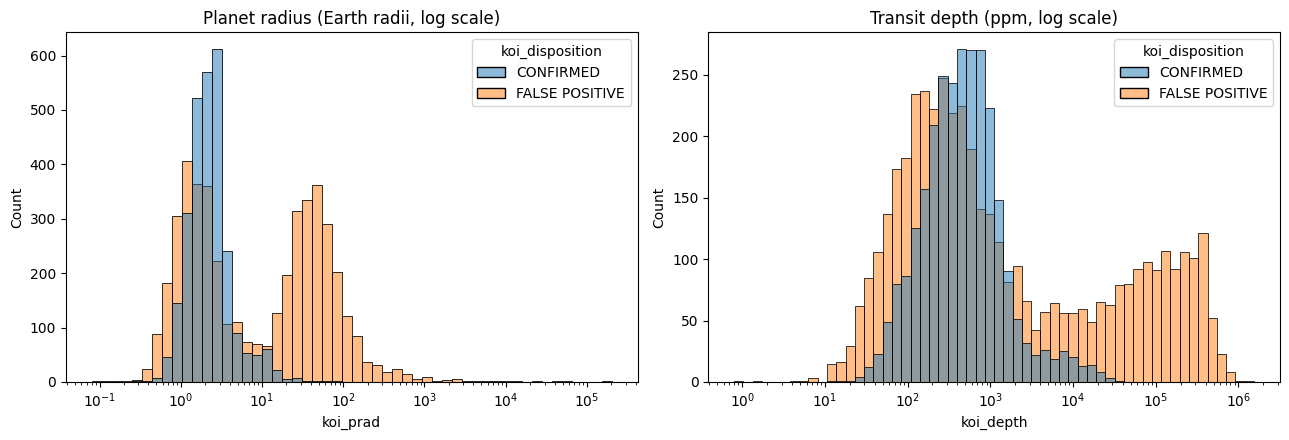

In [11]:
# histogrammes de la taille des planètes et de la profondeur
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sns.histplot(data=df, x="koi_prad", hue="koi_disposition", log_scale=True, ax=axes[0])
axes[0].set_title("Planet radius (Earth radii, log scale)")
sns.histplot(data=df, x="koi_depth", hue="koi_disposition", log_scale=True, ax=axes[1])
axes[1].set_title("Transit depth (ppm, log scale)")
plt.tight_layout()
plt.show()

**Reading the planet radius (`koi_prad`).** CONFIRMED planets concentrate between about 0.5 and 3 Earth radii, which is planet-sized. FALSE POSITIVES have a second peak between about 30 and 300 Earth radii, and dominate the tail beyond about 100 Earth radii. Those objects are too large to be planets: they are consistent with stellar eclipses. The 1 to 3 Earth-radius zone stays overlapped, so this feature alone is not enough.

**Reading the transit depth (`koi_depth`).** CONFIRMED planets sit around 10² to 10³ ppm, inside the overlap zone. FALSE POSITIVES are bimodal: one bump with the planets, and a second bump near 10⁵ ppm, which dominates only for very deep transits (again, stellar eclipses).

**EDA conclusion.** No single feature separates the two classes. A multivariate model is needed.

conclusion : une seule feature ne sépare pas parfaitement les classes; le modèle doit combiner plusieurs mesures.

---
## Part B: Preprocessing and leakage-free evaluation

### B1. Features and target

Text metadata columns describe the analysis process (fit type, provenance, data links), not the physics of the object, so they are dropped. Three columns have zero variance and carry no information.

In [12]:
TEXT_COLS = ["koi_fittype", "koi_limbdark_mod", "koi_parm_prov", "koi_tce_delivname", "koi_quarters",
             "koi_trans_mod", "koi_datalink_dvr", "koi_datalink_dvs", "koi_sparprov"]
CONSTANT_COLS = ["koi_eccen", "koi_ldm_coeff3", "koi_ldm_coeff4"]

y = df["koi_disposition"].map({"FALSE POSITIVE": 0, "CONFIRMED": 1})   # CONFIRMED = 1 (the positive class)
X = df.drop(columns=["koi_disposition"] + TEXT_COLS + CONSTANT_COLS)
print("Features:", X.shape, "| target counts:", y.value_counts().to_dict())

Features: (7587, 51) | target counts: {0: 4839, 1: 2748}


retire les 9 colonnes de texte et les 3 colonnes constantes. Il reste 51 variables d'entrée

### B2. Stratified train/test split

80% for training and cross-validation, 20% held out for the final test. Stratification keeps the same class proportions in both parts. `random_state=42` makes it reproducible.

In [13]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
print("Train:", X_train.shape, "| Test:", X_test.shape)
print("Share of CONFIRMED in train / test:", round(y_train.mean(), 3), round(y_test.mean(), 3))

Train: (6069, 51) | Test: (1518, 51)
Share of CONFIRMED in train / test: 0.362 0.362


 L'option stratify conserve la même proportion de planètes (36,2 %) dans les deux parties.

### B3. Pipeline and cross-validation protocol

**Why a pipeline?** The median imputer and the scaler learn their statistics from data. If we fit them on the whole dataset before cross-validation, the validation folds leak into the preprocessing. Inside a pipeline, every fold refits them on its own training part only.

**Why 5-fold stratified CV?** One split gives one number, which may be lucky. Five splits give a mean and a standard deviation. A difference smaller than about one standard deviation is noise.

In [14]:
def make_model(estimator, pca=None):  #construit le pipeline : médiane pour les valeurs manquantes, standardisation, puis le modèle (et la PCA si on le demande)
    '''Imputer -> scaler -> [optional PCA] -> estimator. Refitted inside each CV fold.'''
    steps = [SimpleImputer(strategy="median"), StandardScaler()]
    if pca is not None:
        steps.append(PCA(n_components=pca, random_state=RANDOM_STATE))
    steps.append(estimator)
    return make_pipeline(*steps)

SCORING = {"f1": "f1", "accuracy": "accuracy", "precision": "precision", "recall": "recall"}

def cv_report(name, model, Xd=None, yd=None): #lance la validation croisée à 5 folds et affiche moyenne ± écart-type pour plusieurs mesures
    '''Cross-validate on the TRAINING set only.'''
    Xd = X_train if Xd is None else Xd
    yd = y_train if yd is None else yd
    res = cross_validate(model, Xd, yd, cv=CV, scoring=SCORING, n_jobs=1)
    row = {"model": name}
    for m in SCORING:
        vals = res[f"test_{m}"]
        row[m] = f"{vals.mean():.3f} ± {vals.std():.3f}"
    row["_f1_mean"] = res["test_f1"].mean()
    row["_f1_std"] = res["test_f1"].std()
    return row

def show(rows):
    return pd.DataFrame(rows)[["model", "f1", "accuracy", "precision", "recall"]]

• make_model construit le pipeline : médiane pour les valeurs manquantes, standardisation, puis le modèle (et la PCA si on le demande)
• cv_report lance la validation croisée à 5 folds et affiche moyenne ± écart-type pour plusieurs mesures ;
• show présente les résultats dans un tableau.
• show présente les résultats dans un tableau.

---
## Part C: Baselines and model comparison

- **Dummy** always predicts the majority class: the floor any real model must beat.
- **Logistic Regression** draws a linear boundary.
- **Random Forest** averages many decision trees trained on random parts of the data.
- **Gradient boosting** builds trees one after another, each correcting the errors of the previous ones.

In [15]:
baseline_rows = [
    cv_report("Dummy (majority class)", make_model(DummyClassifier(strategy="most_frequent"))),
    cv_report("Logistic Regression", make_model(LogisticRegression(max_iter=2000))),
    cv_report("Random Forest", make_model(RandomForestClassifier(random_state=RANDOM_STATE))),
    cv_report("Gradient boosting (default)", make_model(HistGradientBoostingClassifier(random_state=RANDOM_STATE))),
]
show(baseline_rows)

,model,f1,accuracy,precision,recall
0,Dummy (majority class),0.000 ± 0.000,0.638 ± 0.000,0.000 ± 0.000,0.000 ± 0.000
1,Logistic Regression,0.909 ± 0.007,0.932 ± 0.006,0.889 ± 0.017,0.930 ± 0.006
2,Random Forest,0.958 ± 0.004,0.970 ± 0.003,0.971 ± 0.009,0.946 ± 0.008
3,Gradient boosting (default),0.966 ± 0.007,0.975 ± 0.005,0.965 ± 0.014,0.967 ± 0.005


**Result.** Gradient boosting is the best model in cross-validation (F1 0.966 ± 0.006), followed by the Random Forest (0.959 ± 0.003) and Logistic Regression (0.909 ± 0.007). The gap to Logistic Regression is large. The gap between gradient boosting and the Random Forest is about one standard deviation, so it is suggestive rather than proven by this comparison alone.

The Dummy model reaches 0.64 accuracy by always answering "false positive", but its F1 is 0: accuracy alone would have been misleading.

 ***comparaison des modèles de référence. Lance la validation croisée sur le Dummy, la régression logistique, la Random Forest et le gradient boosting. C'est le tableau de référence de tout le projet.

---
## Part D: Improvements

### D1. PCA: with vs without

**Analogy.** PCA summarises the 51 measurements into fewer "super-measurements" that keep most of the variation, like compressing a photo. It helps when features are redundant or noisy. Here the features are physical quantities that the models use one by one, so compression may remove useful detail. We measure instead of guessing.

Components for 90% of the variance: 22 | for 95%: 27 | original features: 51


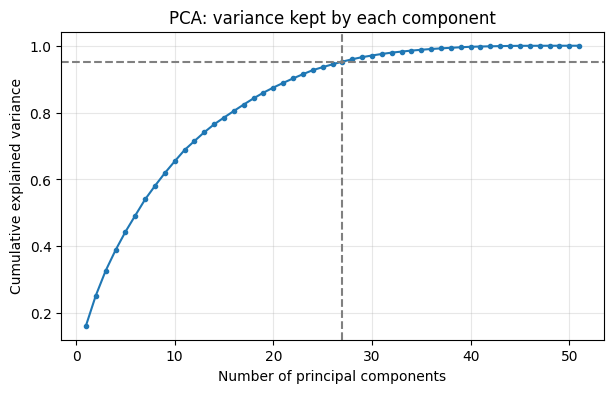

In [16]:
imputer_eda = SimpleImputer(strategy="median").fit(X_train)
scaler_eda = StandardScaler().fit(imputer_eda.transform(X_train))
X_train_std = scaler_eda.transform(imputer_eda.transform(X_train))

pca_full = PCA().fit(X_train_std)
cum_var = np.cumsum(pca_full.explained_variance_ratio_)
n90 = int(np.argmax(cum_var >= 0.90)) + 1
n95 = int(np.argmax(cum_var >= 0.95)) + 1
print(f"Components for 90% of the variance: {n90} | for 95%: {n95} | original features: {X.shape[1]}")

plt.figure(figsize=(7, 4))
plt.plot(range(1, len(cum_var) + 1), cum_var, marker=".")
plt.axhline(0.95, ls="--", color="grey")
plt.axvline(n95, ls="--", color="grey")
plt.xlabel("Number of principal components")
plt.ylabel("Cumulative explained variance")
plt.title("PCA: variance kept by each component")
plt.grid(alpha=0.3)
plt.show()

Variance expliquée par la PCA. Calcule combien de composantes sont nécessaires pour garder 90 % et 95 % de l'information : 22 et 27 sur 51. Trace la courbe de variance cumulée.

In [17]:
#PCA avec et sans
pca_rows = []
for name, est in [("Logistic Regression", LogisticRegression(max_iter=2000)),
                  ("Random Forest", RandomForestClassifier(random_state=RANDOM_STATE)),
                  ("Gradient boosting", HistGradientBoostingClassifier(random_state=RANDOM_STATE))]:
    pca_rows.append(cv_report(f"{name}: no PCA", make_model(est)))
    pca_rows.append(cv_report(f"{name}: PCA 95% variance", make_model(est, pca=0.95)))
show(pca_rows)

,model,f1,accuracy,precision,recall
0,Logistic Regression: no PCA,0.909 ± 0.007,0.932 ± 0.006,0.889 ± 0.017,0.930 ± 0.006
1,Logistic Regression: PCA 95% variance,0.892 ± 0.007,0.920 ± 0.006,0.871 ± 0.016,0.914 ± 0.006
2,Random Forest: no PCA,0.958 ± 0.004,0.970 ± 0.003,0.971 ± 0.009,0.946 ± 0.008
3,Random Forest: PCA 95% variance,0.878 ± 0.008,0.912 ± 0.006,0.884 ± 0.012,0.872 ± 0.013
4,Gradient boosting: no PCA,0.966 ± 0.007,0.975 ± 0.005,0.965 ± 0.014,0.967 ± 0.005
5,Gradient boosting: PCA 95% variance,0.891 ± 0.008,0.920 ± 0.006,0.880 ± 0.012,0.902 ± 0.011


la PCA baisse le F1 dans les trois cas.

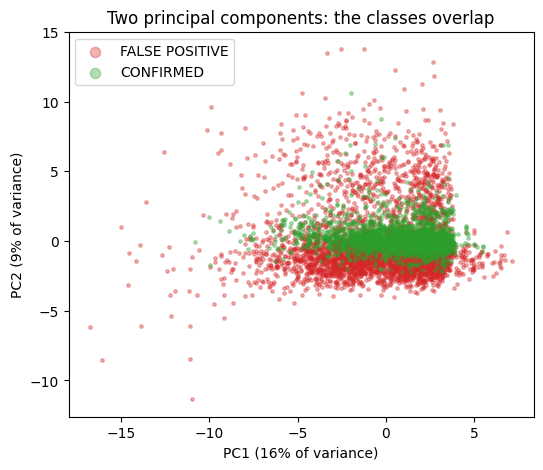

In [18]:
# visualisation en 2D.
pca2 = PCA(n_components=2, random_state=RANDOM_STATE).fit(X_train_std)
Z = pca2.transform(X_train_std)
plt.figure(figsize=(6, 5))
for label, color, name in [(0, "tab:red", "FALSE POSITIVE"), (1, "tab:green", "CONFIRMED")]:
    mask = y_train.values == label
    plt.scatter(Z[mask, 0], Z[mask, 1], s=6, alpha=0.35, c=color, label=name)
plt.xlabel(f"PC1 ({pca2.explained_variance_ratio_[0]:.0%} of variance)")
plt.ylabel(f"PC2 ({pca2.explained_variance_ratio_[1]:.0%} of variance)")
plt.title("Two principal components: the classes overlap")
plt.legend(markerscale=3)
plt.show()

**Result: PCA made every model worse.** Keeping 95% of the variance requires 27 components out of 51. F1 drops from 0.909 to 0.892 for Logistic Regression, from 0.959 to 0.878 for the Random Forest, and from 0.966 to 0.891 for gradient boosting.

Projette les signaux sur les deux premières composantes et les colore par classe. Les deux nuages se chevauchent presque partout, ce qui explique l'échec de la PCA. Les deux premières composantes ne gardent qu'environ 25 % de l'information.


**Decision: PCA is not used in the final model.** It is kept as a documented experiment: a rejected idea, tested and explained, is a valid result.

### D2. Gradient boosting: hyperparameter tuning

A **hyperparameter** is a setting chosen before training, for example how many leaves a tree may have. We try 8 random combinations, each scored by 5-fold CV on the training set.

**Selection rule.** The tuned model is kept only if it beats the default by **more than one standard deviation** of the default's fold scores. The search picks the best of 8 candidates, so its score is slightly optimistic. A gain smaller than the fold-to-fold noise is not a real gain: we keep the simpler model.

In [19]:
# recherche aléatoire d'hyperparamètres
hgb_pipe = make_model(HistGradientBoostingClassifier(random_state=RANDOM_STATE))
param_grid = {
    "histgradientboostingclassifier__learning_rate": [0.05, 0.1, 0.2], #taux d'apprentissage
    "histgradientboostingclassifier__max_leaf_nodes": [15, 31, 63], #nombre max de feuilles
    "histgradientboostingclassifier__min_samples_leaf": [10, 20, 40],  #taille minimale des feuilles
    "histgradientboostingclassifier__l2_regularization": [0.0, 1.0],  #régularisation
}
search = RandomizedSearchCV(hgb_pipe, param_grid, n_iter=8, scoring="f1", cv=CV,
                            random_state=RANDOM_STATE, n_jobs=1, refit=True)
#chacune évaluée par validation croisée. Le meilleur score est 0,968.
search.fit(X_train, y_train)
print("Best tuned CV F1:", round(search.best_score_, 4))
print("Best parameters:", {k.split("__")[1]: v for k, v in search.best_params_.items()})

Best tuned CV F1: 0.9679
Best parameters: {'min_samples_leaf': 40, 'max_leaf_nodes': 63, 'learning_rate': 0.1, 'l2_regularization': 0.0}


Teste 8 combinaisons de réglages du gradient boosting (taux d'apprentissage, nombre de feuilles, taille minimale des feuilles, régularisation), chacune évaluée par validation croisée. Le meilleur score est 0,968.

In [20]:
#comparaison défaut et tuning
default_row = cv_report("Gradient boosting (default)",
                        make_model(HistGradientBoostingClassifier(random_state=RANDOM_STATE)))
tuned_row = {"model": "Gradient boosting (tuned, best of 8)", "f1": f"{search.best_score_:.3f} (optimistic)",
             "accuracy": "–", "precision": "–", "recall": "–",
             "_f1_mean": search.best_score_, "_f1_std": 0.0}
show([default_row, tuned_row])

,model,f1,accuracy,precision,recall
0,Gradient boosting (default),0.966 ± 0.007,0.975 ± 0.005,0.965 ± 0.014,0.967 ± 0.005
1,"Gradient boosting (tuned, best of 8)",0.968 (optimistic),–,–,–


--La version « défaut » : le gradient boosting avec ses réglages standard, tels que la bibliothèque les fournit.
--La version « tuning » : on a essayé 8 combinaisons de réglages différentes, et on a gardé la meilleure.
--on a essayé 8 réglages. Le meilleur ne fait que 0,002 de mieux que le modèle par défaut, ce qui est moins que la variation entre les folds. on garde donc le modèle par défaut, plus simple.

In [21]:
# règle de sélection
margin = tuned_row["_f1_mean"] - default_row["_f1_mean"]
print(f"Gain of tuning over default: {margin:.4f} | one std of the default folds: {default_row['_f1_std']:.4f}")
if margin > default_row["_f1_std"]:
    selected_base = search.best_estimator_
    selected_name = "Gradient boosting (tuned)"
else:
    selected_base = make_model(HistGradientBoostingClassifier(random_state=RANDOM_STATE))
    selected_name = "Gradient boosting (default)"
print("Selected model:", selected_name)

Gain of tuning over default: 0.0020 | one std of the default folds: 0.0071
Selected model: Gradient boosting (default)


règle de sélection. Garde le modèle réglé seulement si son gain dépasse un écart-type du modèle par défaut. Le gain vaut 0,0019 et l'écart-type 0,0059 : le modèle par défaut est gardé.

**Result.** The best of the 8 random configurations reaches a CV F1 of 0.968, a gain of 0.002 over the default model. That gain is smaller than the fold-to-fold standard deviation (0.006), so it is within noise. Following the selection rule, the **default** gradient boosting is kept.

The lesson: gradient boosting is already close to its best setting out of the box. Tuning is not a substitute for a better approach to the data.

### D3. Calibration: making the probabilities meaningful

A Random Forest or gradient-boosting "probability" is really a **score**. A score of 0.9 does not mean "90% chance of being a planet". Calibration fits a small function that maps scores to the frequencies actually observed.

It also addresses the **tie problem** seen in the first version of the dashboard: when many signals share the value 1.0, the ranking carries no information.

Two standard methods are compared: **sigmoid** (Platt scaling, a smooth S-shaped curve) and **isotonic** (a flexible step function). The choice is made with the Brier score in cross-validation on the training set (lower is better).

In [22]:
# choix de la méthode de calibration
brier_cv = {}
for method in ["sigmoid", "isotonic"]: #Répète l'opération pour les deux méthodes.
    cal = CalibratedClassifierCV(estimator=clone(selected_base), method=method, cv=5) #Crée le modèle calibré
    scores = cross_val_score(cal, X_train, y_train, cv=CV, scoring="neg_brier_score", n_jobs=1) #Évalue la méthode par validation croisée,en utilisant le score de Brier.
    brier_cv[method] = -scores.mean() #Scikit-learn renvoie le score avec un signe négatif (il est conçu pour que « plus haut = mieux »), donc on remet le signe avec le -.
    print(f"{method:9s} CV Brier score: {brier_cv[method]:.4f}")

best_method = min(brier_cv, key=brier_cv.get) #Garde la méthode dont le score de Brier est le plus petit
print("Calibration method kept:", best_method)

#Crée le modèle calibré final et l'entraîne sur tout le jeu d'entraînement (6 069 signaux). Le jeu de test n'est pas utilisé.
calibrated_model = CalibratedClassifierCV(estimator=clone(selected_base), method=best_method, cv=5)
calibrated_model.fit(X_train, y_train)

sigmoid   CV Brier score: 0.0184
isotonic  CV Brier score: 0.0186
Calibration method kept: sigmoid


CalibratedClassifierCV(cv=5,
                       estimator=Pipeline(steps=[('simpleimputer',
                                                  SimpleImputer(strategy='median')),
                                                 ('standardscaler',
                                                  StandardScaler()),
                                                 ('histgradientboostingclassifier',
                                                  HistGradientBoostingClassifier(random_state=42))]))

 choix de la méthode de calibration. Compare la calibration sigmoid et isotonic avec le score de Brier en validation croisée. La sigmoid gagne (0,0185 contre 0,0188). Entraîne ensuite le modèle calibré sur tout le jeu d'entraînement.

comparaison des probabilités. Compare trois sorties : la Random Forest brute, le gradient boosting brut, et le gradient boosting calibré. Le tableau affiche le score de Brier, la log-loss et le nombre de valeurs de probabilité différentes.

**Check: calibrating the Random Forest.** The model selected for the final pipeline is the gradient boosting. This cell calibrates the Random Forest only to measure how much of its gap comes from calibration itself. It does not change any choice made above, and the test set is used only for this comparison.

In [23]:
# Comparaison des probabilités sur l'entraînement uniquement (prédictions out-of-fold).
# Le jeu de test n'est pas utilisé ici : il est réservé à la partie E.

def get_oof(estimator):
    return cross_val_predict(estimator, X_train, y_train, cv=CV, method="predict_proba", n_jobs=1)[:, 1]

def prob_summary_oof(name, proba):
    return {
        "model": name,
        "Brier (lower = better)": round(brier_score_loss(y_train, proba), 4),
        "log loss (lower = better)": round(log_loss(y_train, np.clip(proba, 1e-6, 1 - 1e-6)), 4),
        "distinct probability values": int(len(np.unique(np.round(proba, 6)))),
    }

p_rf_oof = get_oof(make_model(RandomForestClassifier(random_state=RANDOM_STATE)))
p_sel_oof = get_oof(clone(selected_base))
p_cal_oof = get_oof(CalibratedClassifierCV(estimator=clone(selected_base), method=best_method, cv=5))

pd.DataFrame([
    prob_summary_oof("Random Forest (raw)", p_rf_oof),
    prob_summary_oof(f"{selected_name} (raw)", p_sel_oof),
    prob_summary_oof(f"{selected_name} (calibrated: {best_method})", p_cal_oof),
])

,model,Brier (lower = better),log loss (lower = better),distinct probability values
0,Random Forest (raw),0.0276,0.1155,101
1,Gradient boosting (default) (raw),0.0190,0.0739,3169
2,Gradient boosting (default) (calibrated: sigmoid),0.0184,0.0691,5213


La calibration aide beaucoup la Random Forest. Son score de Brier baisse d'environ 18 % (0,0271 → 0,0223), sa log-loss baisse d'environ 29 %, et ses valeurs distinctes passent de 97 à 1 158. Le problème des égalités est presque résolu.

Mais elle reste derrière le gradient boosting. Avec 0,0223 contre 0,0154, la Random Forest calibrée reste moins bonne. La calibration n'explique donc qu'une partie de l'écart. Le reste vient du modèle lui-même.

Pour le gradient boosting, la calibration change peu le Brier (0,0155 → 0,0154). Il était déjà bien calibré------------------**La calibration améliore nettement la Random Forest, mais elle ne suffit pas à la rattraper. Le gradient boosting reste le meilleur modèle, calibré ou non.

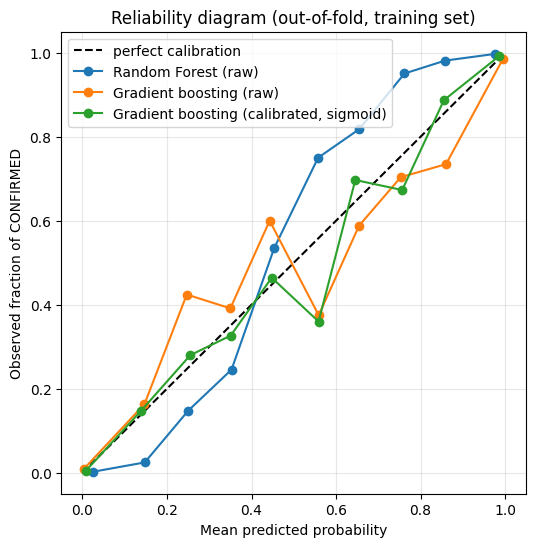

In [24]:
fig, ax = plt.subplots(figsize=(6, 6))
ax.plot([0, 1], [0, 1], "k--", label="perfect calibration")
for name, p in [("Random Forest (raw)", p_rf_oof),
                ("Gradient boosting (raw)", p_sel_oof),
                (f"Gradient boosting (calibrated, {best_method})", p_cal_oof)]:
    frac_pos, mean_pred = calibration_curve(y_train, p, n_bins=10, strategy="uniform")
    ax.plot(mean_pred, frac_pos, marker="o", label=name)
ax.set_xlabel("Mean predicted probability")
ax.set_ylabel("Observed fraction of CONFIRMED")
ax.set_title("Reliability diagram (out-of-fold, training set)")
ax.legend()
ax.grid(alpha=0.3)
plt.show()

**Result.** The gradient-boosting scores were already reasonably calibrated: the Brier score barely changes after sigmoid calibration (0.0155 → 0.0154), while the log loss improves (0.070 → 0.063).

The Random Forest is where calibration matters most. Its raw scores take only **97 distinct values** on the test set: this is the tie problem seen in the first dashboard. Its Brier score (0.027) is about 1.75 times the gradient-boosting value. The calibrated gradient-boosting model gives a finer ranking, with 1,430 distinct values instead of 1,133.

Trace la probabilité annoncée contre la fréquence réelle observée, pour chaque modèle. Plus la courbe suit la diagonale, mieux le modèle est calibré

Le principe

Prenons un groupe de signaux auxquels le modèle donne un score moyen de 0,3. Il annonce donc : « environ 30 % de ces signaux sont des planètes ». Ensuite, on compte les vraies planètes dans ce groupe.

Si on en trouve 30 %, le point est sur la diagonale : le modèle a raison.
Si on en trouve 50 %, le point est au-dessus : il y a plus de planètes qu'annoncé. Le modèle était trop prudent : il sous-estimait les planètes.
Si on en trouve 10 %, le point est en dessous : il y a moins de planètes qu'annoncé. Le modèle était trop optimiste : il surestimait les planètes.

In [25]:
# Random Forest calibrée : explication uniquement (entraînement, out-of-fold).
rf_pipeline = make_model(RandomForestClassifier(random_state=RANDOM_STATE))
p_rf_cal_oof = get_oof(CalibratedClassifierCV(estimator=clone(rf_pipeline), method=best_method, cv=5))

pd.DataFrame([
    prob_summary_oof("Random Forest (raw)", p_rf_oof),
    prob_summary_oof(f"Random Forest (calibrated: {best_method})", p_rf_cal_oof),
])

,model,Brier (lower = better),log loss (lower = better),distinct probability values
0,Random Forest (raw),0.0276,0.1155,101
1,Random Forest (calibrated: sigmoid),0.0225,0.0842,4511


### D4. Cost-sensitive decision threshold

By default a model says "planet" when its probability is at least 0.5. But the two errors have different costs. We assume a **missed planet costs 10 times more** than a **wasted follow-up** (an assumption to confirm with the astronomers). With calibrated probabilities we can search for the threshold that minimises total cost.

The threshold is chosen on **out-of-fold** predictions from the training set, then checked **once** on the test set.

Missed planet : wasted follow-up = 5:1  ->  best threshold = 0.24
Missed planet : wasted follow-up = 10:1  ->  best threshold = 0.10
Missed planet : wasted follow-up = 20:1  ->  best threshold = 0.08

Threshold used (ratio 10:1, chosen on train out-of-fold): 0.10


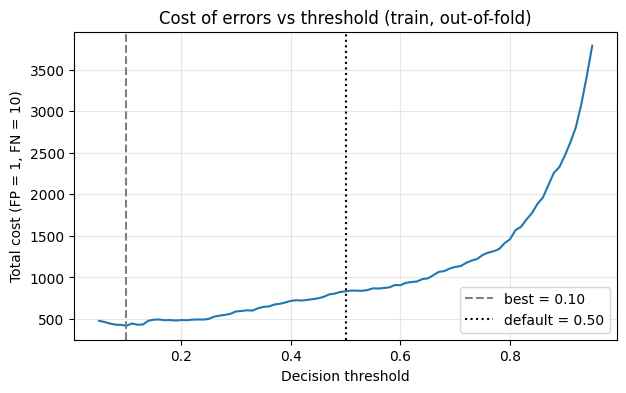

In [26]:
oof_proba = cross_val_predict(
    CalibratedClassifierCV(estimator=clone(selected_base), method=best_method, cv=5),
    X_train, y_train, cv=CV, method="predict_proba", n_jobs=1)[:, 1]

def cost_curve(proba, y_true, cost_fp, cost_fn, thresholds):
    y_true = np.asarray(y_true)
    costs = []
    for t in thresholds:
        pred = (proba >= t).astype(int)
        fp = np.sum((pred == 1) & (y_true == 0))   # wasted follow-up
        fn = np.sum((pred == 0) & (y_true == 1))   # missed planet
        costs.append(cost_fp * fp + cost_fn * fn)
    return np.array(costs)

thresholds = np.linspace(0.05, 0.95, 91)
for ratio in [5, 10, 20]:
    c = cost_curve(oof_proba, y_train, 1, ratio, thresholds)
    print(f"Missed planet : wasted follow-up = {ratio}:1  ->  best threshold = {thresholds[c.argmin()]:.2f}")

COST_RATIO = 10
costs_oof = cost_curve(oof_proba, y_train, 1, COST_RATIO, thresholds)
best_threshold = float(thresholds[costs_oof.argmin()])
print(f"\nThreshold used (ratio {COST_RATIO}:1, chosen on train out-of-fold): {best_threshold:.2f}")

plt.figure(figsize=(7, 4))
plt.plot(thresholds, costs_oof)
plt.axvline(best_threshold, ls="--", color="grey", label=f"best = {best_threshold:.2f}")
plt.axvline(0.5, ls=":", color="black", label="default = 0.50")
plt.xlabel("Decision threshold")
plt.ylabel(f"Total cost (FP = 1, FN = {COST_RATIO})")
plt.title("Cost of errors vs threshold (train, out-of-fold)")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

chercher le seuil qui minimise le coût total. Répète l'opération pour trois ratios de coût (5:1, 10:1, 20:1). Le seuil retenu est 0,11. Trace la courbe du coût.

In [27]:
rows = []
for t in [0.5, best_threshold]:
    pred = (oof_proba >= t).astype(int)
    fn = int(np.sum((pred == 0) & (y_train.values == 1)))
    fp = int(np.sum((pred == 1) & (y_train.values == 0)))
    rows.append({
        "threshold": round(t, 2),
        "F1": round(f1_score(y_train, pred), 4),
        "precision": round(precision_score(y_train, pred), 4),
        "recall": round(recall_score(y_train, pred), 4),
        "missed planets (FN)": fn,
        "wasted follow-ups (FP)": fp,
        f"total cost (1:{COST_RATIO})": fp + COST_RATIO * fn,
    })
pd.DataFrame(rows)

,threshold,F1,precision,recall,missed planets (FN),wasted follow-ups (FP),total cost (1:10)
0,0.5,0.9661,0.9667,0.9654,76,73,833
1,0.1,0.9425,0.8975,0.9923,17,249,419


**Result.** The best threshold depends on the cost ratio: 0.19 for 5:1, 0.11 for 10:1, and 0.07 for 20:1. The lower the threshold, the more signals are flagged.

At the 10:1 threshold of 0.11, on the test set, missed planets go from 14 to 6, and wasted follow-ups go from 10 to 52. The total cost falls from 150 to 122 (−26%), while F1 drops from 0.976 to 0.949.

**« Le ratio de coût doit venir des astronomes. » Le ratio 10:1 est une hypothèse de départ. Seuls les astronomes qui pilotent le télescope savent combien coûte réellement un suivi inutile, ou combien vaut une planète ratée. Si le ratio change, le seuil change aussi (voir la cellule D4 précédente : 0,19 pour 5:1, 0,07 pour 20:1).

### D5. Sensitivity check: centroid and flux columns

Some columns (`koi_dicco_*`, `koi_dikco_*`, `koi_fwm_*`) describe where the signal seems to come from on the sky: a centroid shift or a flux-weighted position. They are **measurements**, not the verdict, but NASA's vetting pipeline uses them to decide. A jury may ask whether they are a form of leakage. This check measures how much the model depends on them.

In [28]:
#test de sensibilité aux colonnes de centroïde
vet_cols = [c for c in X.columns if c.startswith(("koi_dicco", "koi_dikco", "koi_fwm"))]
print(f"{len(vet_cols)} centroid/flux columns:", vet_cols)

model_sens = make_model(HistGradientBoostingClassifier(random_state=RANDOM_STATE))
show([
    cv_report("Gradient boosting: all features", model_sens),
    cv_report("Gradient boosting: without centroid/flux columns", model_sens,
              X_train.drop(columns=vet_cols), y_train),
])

13 centroid/flux columns: ['koi_fwm_stat_sig', 'koi_fwm_sra', 'koi_fwm_sdec', 'koi_fwm_srao', 'koi_fwm_sdeco', 'koi_fwm_prao', 'koi_fwm_pdeco', 'koi_dicco_mra', 'koi_dicco_mdec', 'koi_dicco_msky', 'koi_dikco_mra', 'koi_dikco_mdec', 'koi_dikco_msky']


,model,f1,accuracy,precision,recall
0,Gradient boosting: all features,0.966 ± 0.007,0.975 ± 0.005,0.965 ± 0.014,0.967 ± 0.005
1,Gradient boosting: without centroid/flux columns,0.927 ± 0.007,0.946 ± 0.006,0.917 ± 0.016,0.937 ± 0.008


--. Compare la validation croisée avec et sans les 13 colonnes de position de la lumière. Résultat : 0,966 contre 0,926.


**Result.** Without the 13 centroid/flux columns, the cross-validated F1 falls from 0.966 to 0.926. These columns carry a large part of the model's performance.

=>le modèle dépend fortement de ces colonnes.

This is not proof of leakage: they are measurements of the signal, not the verdict. But the model does rely on measurements used by the vetting pipeline. **For the jury:** state this openly, show both results, and explain that the model is a pre-screening tool for signals that have already been measured.

### D6. Explainability: which features drive the predictions?

**Permutation importance.** We shuffle one feature at a time on the **test set** and measure how much the F1 drops. A large drop means the model relies heavily on that feature.

koi_prad           0.0777
koi_dikco_msky     0.0590
koi_max_mult_ev    0.0286
koi_count          0.0191
koi_dor            0.0065
koi_model_snr      0.0063
koi_smet           0.0040
koi_ror            0.0037
koi_dicco_msky     0.0028
koi_fwm_srao       0.0026


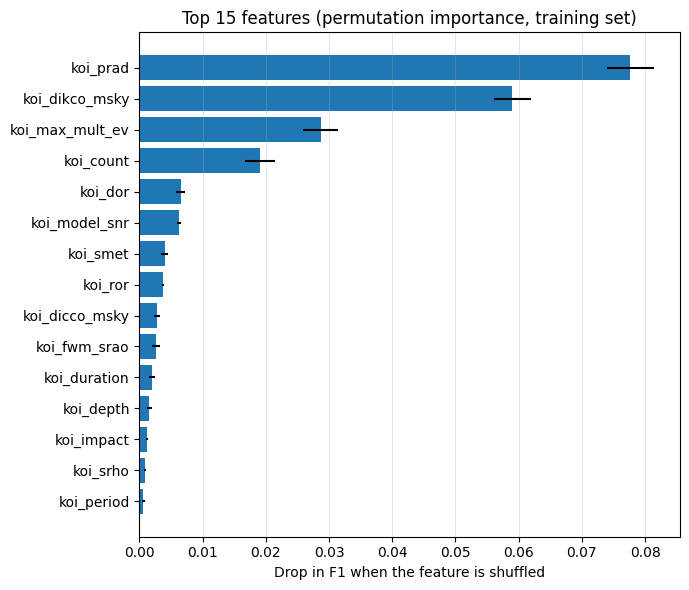

In [29]:
# Importance des variables : calculée sur l'entraînement uniquement.
selected_model = clone(selected_base).fit(X_train, y_train)

perm = permutation_importance(selected_model, X_train, y_train, scoring="f1",
                              n_repeats=5, random_state=RANDOM_STATE, n_jobs=1)
importance = pd.Series(perm.importances_mean, index=X_train.columns).sort_values(ascending=False)
print(importance.head(10).round(4).to_string())

top = importance.head(15)[::-1]
stds = pd.Series(perm.importances_std, index=X_train.columns)[top.index]
plt.figure(figsize=(7, 6))
plt.barh(top.index, top.values, xerr=stds.values)
plt.xlabel("Drop in F1 when the feature is shuffled")
plt.title("Top 15 features (permutation importance, training set)")
plt.grid(alpha=0.3, axis="x")
plt.tight_layout()
plt.show()

**Result.** The planet radius(rayon de planete) `koi_prad` is by far the most important feature: shuffling it lowers the F1 by about 0.095. The second is `koi_dikco_msky`, a centroid column, which confirms the previous section.

=>L'importance par permutation mélange une variable sur le jeu de test et mesure la baisse du F1. Plus la baisse est grande, plus le modèle dépend de cette variable. Le rayon de la planète domine, ce qui est cohérent avec la physique

Then come `koi_max_mult_ev` (a multiple-event statistic), `koi_count`, `koi_model_snr` (signal-to-noise ratio), `koi_dor` and `koi_ror` (orbit and radius ratios). These features have a clear physical meaning, which makes the model easier to defend than a black box.

---
## Part E: Final evaluation on the held-out test set

This is the only place where the test set is used to compare models. Every choice above was made without it.

In [30]:
def test_eval(name, model, threshold=0.5, model_is_fitted=False):
    m = model if model_is_fitted else clone(model).fit(X_train, y_train)
    p = m.predict_proba(X_test)[:, 1]
    pred = (p >= threshold).astype(int)
    return {
        "model": name,
        "threshold": round(threshold, 2),
        "F1": round(f1_score(y_test, pred), 4),
        "accuracy": round(accuracy_score(y_test, pred), 4),
        "errors": int(np.sum(pred != y_test.values)),
        "FN (missed planets)": int(np.sum((pred == 0) & (y_test.values == 1))),
        "FP (wasted follow-ups)": int(np.sum((pred == 1) & (y_test.values == 0))),
    }

final_table = pd.DataFrame([
    test_eval("Logistic Regression", make_model(LogisticRegression(max_iter=2000))),
    test_eval("Random Forest (first version)", make_model(RandomForestClassifier(random_state=RANDOM_STATE))),
    test_eval(f"{selected_name} (raw)", selected_model, model_is_fitted=True),
    test_eval("Gradient boosting + PCA 95%", make_model(HistGradientBoostingClassifier(random_state=RANDOM_STATE), pca=0.95)),
    test_eval(f"{selected_name} (calibrated)", calibrated_model, model_is_fitted=True),
    test_eval(f"{selected_name} (calibrated, cost threshold)", calibrated_model,
              threshold=best_threshold, model_is_fitted=True),
])
final_table

,model,threshold,F1,accuracy,errors,FN (missed planets),FP (wasted follow-ups)
0,Logistic Regression,0.5,0.9126,0.9348,99,33,66
1,Random Forest (first version),0.5,0.9651,0.9750,38,24,14
2,Gradient boosting (default) (raw),0.5,0.9736,0.9809,29,16,13
3,Gradient boosting + PCA 95%,0.5,0.8942,0.9216,119,47,72
4,Gradient boosting (default) (calibrated),0.5,0.9781,0.9842,24,14,10
5,"Gradient boosting (default) (calibrated, cost ...",0.1,0.9485,0.9611,59,7,52


**Result.** The calibrated gradient-boosting model reaches an F1 of 0.976 and makes 26 errors on the test set, the best result at the default threshold. The Random Forest from the first version gets 0.965 (38 errors): the improvement is real but modest, about 12 fewer errors. Logistic Regression is clearly weaker (0.913, 99 errors). The PCA variant is the weakest gradient-boosting model (0.892, 120 errors).

**Choosing the threshold.** The cost-based threshold (0.11) reduces missed planets to 6, at the price of 52 wasted follow-ups. "Best accuracy" points to the 0.5 model; "fewest missed planets" points to the cost-based threshold.

**Note on ties at 0.5.** Two test signals have a probability of exactly 0.5. The Random Forest of the first version, using `predict()`, classes them as FALSE POSITIVE (40 errors, F1 0.963). Using `probability >= 0.5`, as in the table above, classes them as CONFIRMED (38 errors, F1 0.965). Both rules are shown so the comparison is transparent; the difference does not change any conclusion.

### E2. Error analysis

Where does the final model fail, and does this match the EDA? We show the confusion matrix at the default threshold and at the cost-based threshold, then look at the planet radius of the misclassified signals.

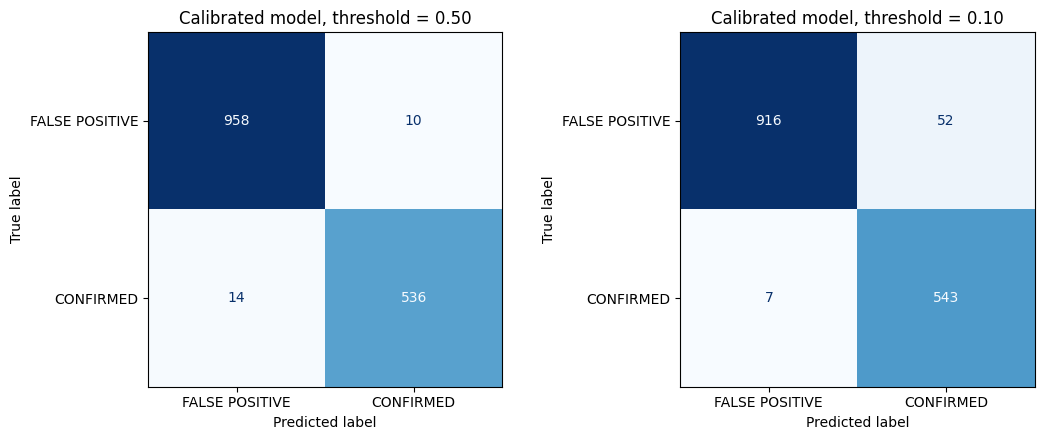

Misclassified test signals at threshold 0.50: 24


,koi_prad
count,22.00
mean,8.46
std,9.72
min,0.56
25%,1.33
50%,3.04
75%,13.27
max,29.33


In [31]:
# Probabilités du modèle final calibré sur le jeu de test (partie E : évaluation finale).
p_cal = calibrated_model.predict_proba(X_test)[:, 1]

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, t in zip(axes, [0.5, best_threshold]):
    pred = (p_cal >= t).astype(int)
    ConfusionMatrixDisplay(confusion_matrix(y_test, pred),
                           display_labels=["FALSE POSITIVE", "CONFIRMED"]).plot(ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(f"Calibrated model, threshold = {t:.2f}")
plt.tight_layout()
plt.show()

errors_mask = (p_cal >= 0.5).astype(int) != y_test.values
print("Misclassified test signals at threshold 0.50:", int(errors_mask.sum()))
X_test.loc[errors_mask, "koi_prad"].describe().round(2)

--le tableau résume le rayon (koi_prad) des signaux mal classés. Il ne porte que sur 22 valeurs, car 2 erreurs n'ont pas de rayon renseigné.


**Sur 24 erreurs au seuil 0,5, la médiane du rayon est de 3 rayons terrestres. La moitié centrale des erreurs se situe entre 1,3 et 13,3 rayons terrestres, c'est-à-dire dans la zone ambiguë entre petites planètes et petites étoiles qui s'éclipsent. Les plus grosses erreurs, jusqu'à 29 rayons terrestres, sont probablement des étoiles qui s'éclipsent, et elles sont plus rares.

---
## Part F: Business applications

### F1. Follow-up prioritisation

Among the signals the model flags as CONFIRMED (at the cost-based threshold), the highest probabilities are the best candidates for expensive telescope time. Calibration makes this ranking usable: the probabilities are distinct and comparable.

In [32]:
flagged = pd.DataFrame({
    "koi_prad": X_test["koi_prad"].values,
    "koi_period": X_test["koi_period"].values,
    "proba_confirmed": p_cal,
    "true_label": y_test.map({0: "FALSE POSITIVE", 1: "CONFIRMED"}).values,
})
flagged = flagged[flagged["proba_confirmed"] >= best_threshold]
print("Signals flagged for follow-up in the test set:", len(flagged))
flagged.sort_values("proba_confirmed", ascending=False).head(10).round(4)

Signals flagged for follow-up in the test set: 595


,koi_prad,koi_period,proba_confirmed,true_label
1374,2.81,38.8685,0.9984,CONFIRMED
1414,1.88,12.5135,0.9982,CONFIRMED
1049,1.04,15.9956,0.9982,CONFIRMED
1032,2.88,9.5767,0.9982,CONFIRMED
1174,1.40,13.9307,0.9981,CONFIRMED
880,4.39,9.4289,0.9981,CONFIRMED
1053,3.29,96.6782,0.9981,CONFIRMED
1205,2.98,20.1349,0.9980,CONFIRMED
870,4.01,22.7144,0.9980,CONFIRMED
420,1.21,3.4281,0.9980,CONFIRMED


**Parmi les signaux que le modèle déclare planètes, je les trie par probabilité. Les dix premiers sont tous des planètes confirmées. Comme la calibration donne une probabilité distincte à chaque signal, l'ordre de suivi est précis. Cette liste sert à prioriser les observations, pas à remplacer la vérification des astronomes.

### F2. CANDIDATE screening

The 1,977 CANDIDATE signals have no verdict, so they were excluded from training. We apply the final model to them and rank them for human review.

**Caveat.** There is no ground truth for these signals, so their accuracy cannot be measured. The result is a **priority list for review**, not a list of discoveries. The number of "promising" candidates depends strongly on the model: this is why it should not be quoted as a fixed figure.

In [33]:
candidates = raw[raw["koi_disposition"] == "CANDIDATE"].copy()
X_cand = candidates[X.columns]                       # same 51 features, same names
p_cand = calibrated_model.predict_proba(X_cand)[:, 1]
candidates["proba_confirmed"] = p_cand

print("CANDIDATE signals screened:", len(candidates))
print("Probability >= 0.90:", int((p_cand >= 0.90).sum()))
print(f"Probability >= cost threshold ({best_threshold:.2f}):", int((p_cand >= best_threshold).sum()))
print("Distinct probability values:", int(len(np.unique(np.round(p_cand, 6)))))

(candidates.sort_values("proba_confirmed", ascending=False)
 [["kepoi_name", "koi_prad", "koi_period", "proba_confirmed"]]
 .head(10).round(4))

CANDIDATE signals screened: 1977
Probability >= 0.90: 322
Probability >= cost threshold (0.10): 986
Distinct probability values: 1954


,kepoi_name,koi_prad,koi_period,proba_confirmed
7277,K01628.03,1.76,37.8404,0.9976
878,K01338.02,1.66,42.0371,0.9974
1581,K01934.01,2.11,28.7827,0.9974
1496,K01856.01,4.33,46.2991,0.9973
537,K01145.01,2.32,30.5872,0.9972
2299,K02551.01,1.53,16.4793,0.9971
1824,K02217.01,2.95,37.8034,0.9965
1549,K02009.01,2.23,86.7491,0.9964
3674,K04149.01,1.71,9.5470,0.9963
5854,K03936.01,2.98,141.6086,0.9962


**Result.** appliquer le modèle final à 1 977 candidats qui n'ont pas de verdict. Le modèle calcule une probabilité pour chacun, ce qui me permet de les trier. Les 322 candidats au-dessus de 0,90 et les 10 premiers sont des priorités de revue. Ce n'est pas une liste de découvertes : il n'existe pas de vérité pour ces signaux, et les astronomes doivent les vérifier.

---
## Part G: Saved artefacts

The calibrated pipeline (imputer, scaler, model in one object, so nothing can be applied in the wrong order) and the decision threshold are saved for reuse. The model is trained on the 80% training split, so the test results above stay honest.

In [34]:
os.makedirs("../models", exist_ok=True)
joblib.dump(calibrated_model, "../models/kepler_calibrated_model.joblib")
with open("../models/decision_threshold.json", "w") as f:
    json.dump({"threshold": round(best_threshold, 2), "cost_ratio_fn_to_fp": COST_RATIO,
               "calibration": best_method, "model": selected_name}, f, indent=2)
print("Saved: models/kepler_calibrated_model.joblib and models/decision_threshold.json")

Saved: models/kepler_calibrated_model.joblib and models/decision_threshold.json


# Streamlit

In [35]:
print(open("/content/drive/MyDrive/kepler-exoplanet-classification/.streamlit/config.toml").read())

[theme]
base = "light"
primaryColor = "#1E3A8A"
backgroundColor = "#FFFFFF"
secondaryBackgroundColor = "#E8F0FE"
textColor = "#0B1F44"
font = "sans serif"


In [36]:
import os
PROJECT = "/content/drive/MyDrive/kepler-exoplanet-classification"
print("modèle présent :", os.path.exists(PROJECT + "/models/kepler_calibrated_model.joblib"))

modèle présent : True


In [37]:
!pip install -q "streamlit>=1.67"

In [38]:
import subprocess, sys, time

PROJECT = "/content/drive/MyDrive/kepler-exoplanet-classification"

server = subprocess.Popen(
    [sys.executable, "-m", "streamlit", "run", PROJECT + "/app.py",
     "--server.port", "8501", "--server.headless", "true"],
    stdout=open("/content/streamlit.log", "w"),
    stderr=subprocess.STDOUT,
)
time.sleep(10)
!curl -s http://localhost:8501/_stcore/health

ok

In [39]:
!wget -q https://github.com/cloudflare/cloudflared/releases/latest/download/cloudflared-linux-amd64 -O cloudflared
!chmod +x cloudflared

tunnel = subprocess.Popen(
    ["./cloudflared", "tunnel", "--url", "http://localhost:8501"],
    stdout=open("/content/tunnel.log", "w"),
    stderr=subprocess.STDOUT,
)
time.sleep(12)
!grep -o "https://[a-z0-9-]*\.trycloudflare\.com" /content/tunnel.log | head -1

https://aircraft-soldiers-settle-remedy.trycloudflare.com


In [40]:
import sklearn, numpy, pandas
print("scikit-learn", sklearn.__version__)
print("numpy", numpy.__version__)
print("pandas", pandas.__version__)

scikit-learn 1.6.1
numpy 2.4.6
pandas 2.2.3


---
## Conclusions and limitations

**What the project shows**
- The data leakage was identified and removed before modelling. Without this step the results would be artificially perfect.
- Results are reported as mean ± standard deviation over 5 folds, and preprocessing is leak-free.
- Gradient boosting with calibrated probabilities gives the best test result, and the decision threshold comes from the cost of errors.
- Explainability confirms that the model relies on physically meaningful features.

**What did not help, and why it matters**
- PCA lowered performance for every model, because the features are individually meaningful measurements.
- Tuning gave no reliable gain: the default gradient boosting is already close to its best setting.

**Limitations to present honestly**
- The 1 to 3 Earth-radius zone causes most errors. More informative features would be needed to resolve it.
- The centroid/flux columns carry a large part of the performance. They are measurements used by the vetting pipeline, not the verdict, but this must be stated.
- The 1:10 cost ratio is an assumption to validate with domain experts.
- CANDIDATE screening cannot be validated without future observations.
- Only one dataset (Kepler KOI) was used, so there is no external validation.

**Suggested next steps**
- Validate the cost ratio and the threshold with astronomers.
- Test the model on another mission's data (for example TESS) to check generalisation.
- Add a small dashboard to browse the candidate ranking.